# Explainable AI for Diabetic Retinopathy Screening
### Multi-architecture comparison: EfficientNetB0 vs ResNet50 vs DenseNet121 (+ ensemble)

Five-class grading of retinal fundus images (**No DR, Mild, Moderate, Severe, Proliferative DR**) with transfer learning,
focused on **referable DR** triage (Moderate or worse) for rural screening camps.

**Dataset:** [APTOS 2019, 224x224 Gaussian-filtered](https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered) (3,662 images)

| Model | Why it is here |
|---|---|
| **EfficientNetB0** | Compound-scaled CNN. Best accuracy-per-parameter, suited to edge devices |
| **ResNet50** | Residual-learning baseline, widely used in medical-imaging literature |
| **DenseNet121** | Dense connections reuse fine features (micro-aneurysms, exudates). The reference CNN of CheXNet |
| **Soft-voting ensemble** | Averages the three models' probabilities to reduce variance |

### Pipeline
1. Setup and configuration
2. Data: stratified **train / validation / test** split (70 / 15 / 15), EDA
3. Input pipeline: cached `tf.data`, augmentation, model-specific preprocessing
4. Model factory: one function builds any of the three backbones
5. Two-stage training: frozen-backbone warm-up, then fine-tuning (class weights, early stopping, LR scheduling)
6. Evaluation on the **held-out test set**: Accuracy, Macro-F1, **Quadratic Weighted Kappa**, referable-DR **ROC-AUC / Sensitivity / Specificity**
7. Ensemble
8. Model comparison: tables, charts, confusion matrices, ROC curves, efficiency
9. Grad-CAM explainability, all three models side by side
10. Screening demo: one image to triage decision with heatmap

> Run all cells top to bottom on a GPU runtime (Colab: *Runtime > Change runtime type > T4 GPU*). Total run time is about 25-35 min.

## 1. Setup

In [4]:
!pip install -q kagglehub

In [5]:
import os, time, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from keras.applications import EfficientNetB0, ResNet50, DenseNet121
from keras.applications import efficientnet, resnet50, densenet

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (training will be slow)")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
# ------------------------------------------------------------------ configuration
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
SEED        = 42
WEIGHTS     = "imagenet"

HEAD_EPOCHS = 8      # stage 1: frozen backbone, train the classification head
FT_EPOCHS   = 15     # stage 2: fine-tune the top of the backbone (early stopping usually ends it sooner)
HEAD_LR     = 1e-3
FT_LR       = 1e-4

TARGET_SENSITIVITY = 0.90   # referable-DR operating point, chosen on the validation set

USE_DRIVE = False
keras.utils.set_random_seed(SEED)

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/DR_Project_MultiModel"
else:
    OUTPUT_DIR = "./DR_Project_MultiModel"

for sub in ("models", "figures", "metrics"):
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

def out(*parts):
    return os.path.join(OUTPUT_DIR, *parts)

def savefig(name):
    plt.savefig(out("figures", name), dpi=300, bbox_inches="tight")

print("Outputs ->", os.path.abspath(OUTPUT_DIR))

Outputs -> /content/DR_Project_MultiModel


## 2. Data

In [7]:
import kagglehub
path = kagglehub.dataset_download("sovitrath/diabetic-retinopathy-224x224-gaussian-filtered")

# Clinical order, so label index = DR grade (needed for Quadratic Weighted Kappa)
CLASS_DIRS  = ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]
CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
NUM_CLASSES = len(CLASS_NAMES)
REFERABLE   = [2, 3, 4]          # Moderate or worse -> refer to ophthalmologist

DATASET = next(root for root, dirs, _ in os.walk(path) if set(CLASS_DIRS).issubset(dirs))

records = [
    (os.path.join(DATASET, d, f), grade)
    for grade, d in enumerate(CLASS_DIRS)
    for f in sorted(os.listdir(os.path.join(DATASET, d)))
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]
df = pd.DataFrame(records, columns=["path", "label"])
print(f"{len(df)} images found in {DATASET}")

100%|██████████| 427M/427M [00:21<00:00, 20.5MB/s]

Extracting files...


3662 images found in /root/.cache/kagglehub/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered/versions/2/gaussian_filtered_images/gaussian_filtered_images


### 2.1 Stratified train / validation / test split
The original notebook evaluated on the same split it used for model selection. Here the **validation** set is used for early
stopping and threshold tuning, and the **test** set is touched only once, for the final numbers.

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df,   test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
SPLITS = {"train": train_df.reset_index(drop=True),
          "val":   val_df.reset_index(drop=True),
          "test":  test_df.reset_index(drop=True)}

dist = pd.DataFrame({k: v.label.value_counts().sort_index() for k, v in SPLITS.items()})
dist.index = CLASS_NAMES
dist.loc["Total"] = dist.sum()
dist

,train,val,test
No DR,1263,271,271
Mild,259,55,56
Moderate,699,150,150
Severe,135,29,29
Proliferative,207,44,44
Total,2563,549,550


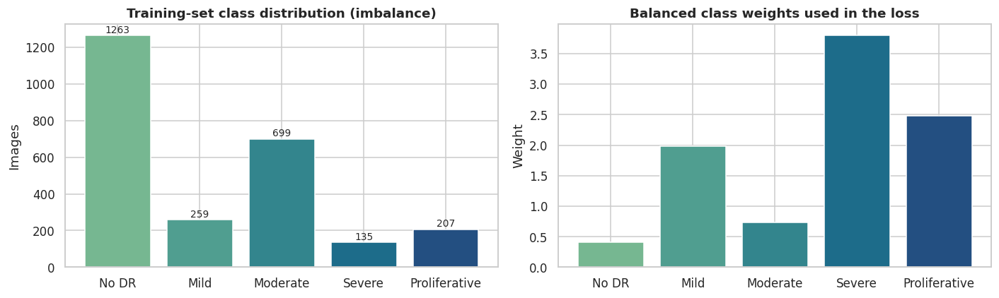

Imbalance ratio (largest / smallest class): 9.4


In [9]:
# Class weights: inverse frequency, computed on the training split only
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=SPLITS["train"].label)
CLASS_WEIGHTS = dict(enumerate(weights.astype(float)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts = SPLITS["train"].label.value_counts().sort_index()
palette = sns.color_palette("crest", NUM_CLASSES)
ax[0].bar(CLASS_NAMES, counts, color=palette)
for i, c in enumerate(counts):
    ax[0].text(i, c + 15, str(c), ha="center", fontsize=9)
ax[0].set_title("Training-set class distribution (imbalance)")
ax[0].set_ylabel("Images")
ax[1].bar(CLASS_NAMES, weights, color=palette)
ax[1].set_title("Balanced class weights used in the loss")
ax[1].set_ylabel("Weight")
plt.tight_layout(); savefig("class_distribution.png"); plt.show()

print("Imbalance ratio (largest / smallest class):", round(counts.max() / counts.min(), 1))

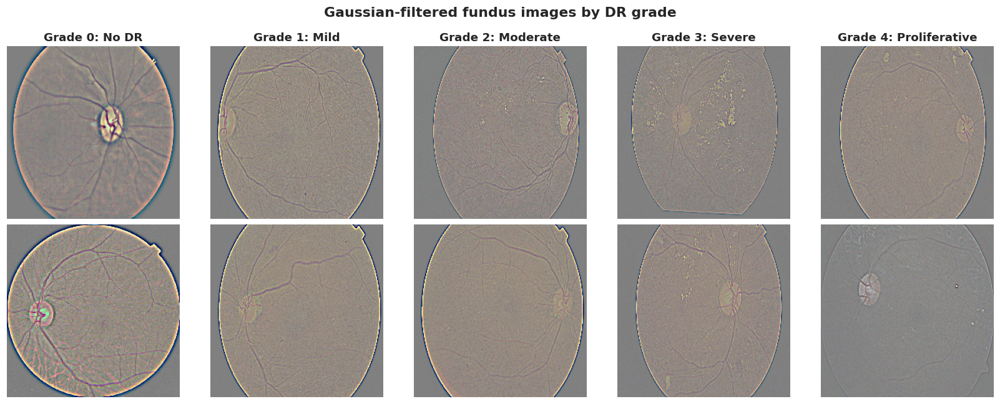

In [10]:
# Two sample images per grade
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(15, 6))
for grade in range(NUM_CLASSES):
    sample = SPLITS["train"][SPLITS["train"].label == grade].sample(2, random_state=SEED)
    for row, p in enumerate(sample.path):
        axes[row, grade].imshow(plt.imread(p))
        axes[row, grade].axis("off")
    axes[0, grade].set_title(f"Grade {grade}: {CLASS_NAMES[grade]}")
plt.suptitle("Gaussian-filtered fundus images by DR grade", fontweight="bold")
plt.tight_layout(); savefig("sample_images.png"); plt.show()

## 3. Input pipeline
Images are decoded once and **cached in memory**. Each backbone was pre-trained with a different input normalisation,
so the matching `preprocess_input` is applied per model. Augmentation reflects fundus photography: any orientation,
slight zoom, and lighting changes between cameras.

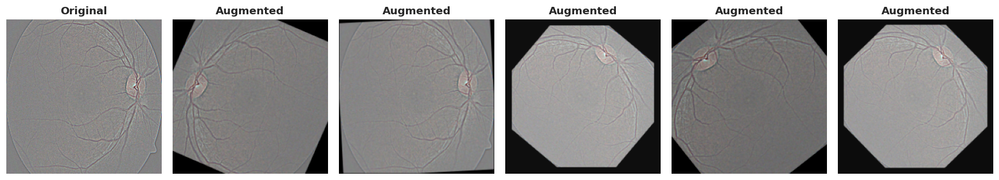

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label=None):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)
    return img if label is None else (img, label)

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.15, fill_mode="constant", seed=SEED),
    layers.RandomZoom(0.10, fill_mode="constant", seed=SEED),
    layers.RandomBrightness(0.10, value_range=(0, 255), seed=SEED),
    layers.RandomContrast(0.10, seed=SEED),
], name="augmentation")

# Decoded once per split, then shared by every model
CACHED = {
    name: tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values))
            .map(load_image, num_parallel_calls=AUTOTUNE).cache()
    for name, d in SPLITS.items()
}

def make_dataset(split, preprocess, training=False):
    ds = CACHED[split]
    if training:
        ds = ds.shuffle(len(SPLITS[split]), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

# Preview augmentation
img, _ = load_image(SPLITS["train"].path[0], 0)
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(img); axes[0].set_title("Original")
for ax in axes[1:]:
    ax.imshow(tf.cast(tf.clip_by_value(augment(tf.cast(img[None], tf.float32), training=True)[0], 0, 255), tf.uint8))
    ax.set_title("Augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); savefig("augmentation_preview.png"); plt.show()

## 4. Model factory
All three models share the same head, so the comparison isolates the **backbone**:

`Input 224x224x3 -> Backbone (ImageNet) -> GlobalAvgPool -> Dropout(0.3) -> Dense(256, ReLU) -> Dropout(0.3) -> Dense(5, softmax)`

The backbone is called with `training=False`, so its BatchNorm statistics stay frozen during fine-tuning (standard Keras practice; it avoids
corrupting ImageNet statistics with small batches).

In [12]:
MODEL_ZOO = {
    "EfficientNetB0": dict(builder=EfficientNetB0, preprocess=efficientnet.preprocess_input, fine_tune_layers=60),
    "ResNet50":       dict(builder=ResNet50,       preprocess=resnet50.preprocess_input,     fine_tune_layers=40),
    "DenseNet121":    dict(builder=DenseNet121,    preprocess=densenet.preprocess_input,     fine_tune_layers=60),
}
MODEL_COLORS = {"EfficientNetB0": "#2a9d8f", "ResNet50": "#e76f51", "DenseNet121": "#457b9d", "Ensemble": "#6d597a"}


def build_model(name):
    spec = MODEL_ZOO[name]
    backbone = spec["builder"](include_top=False, weights=WEIGHTS, input_shape=(*IMG_SIZE, 3))
    backbone.trainable = False

    head = [
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dropout(0.3, name="dropout_1"),
        layers.Dense(256, activation="relu", name="dense_256"),
        layers.Dropout(0.3, name="dropout_2"),
        layers.Dense(NUM_CLASSES, activation="softmax", name="predictions"),
    ]
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="fundus_image")
    x = backbone(inputs, training=False)
    for layer in head:
        x = layer(x)
    return keras.Model(inputs, x, name=name), backbone, head


def unfreeze_top(backbone, n_layers):
    backbone.trainable = True
    for layer in backbone.layers[:-n_layers]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def count_params(model):
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    total = sum(int(np.prod(w.shape)) for w in model.weights)
    return total, trainable


summary = []
for name in MODEL_ZOO:
    m, bb, _ = build_model(name)
    total, _ = count_params(m)
    summary.append({"Model": name, "Backbone layers": len(bb.layers),
                    "Feature map": "x".join(map(str, bb.output.shape[1:])),
                    "Total params (M)": round(total / 1e6, 2)})
    del m, bb
keras.backend.clear_session()
pd.DataFrame(summary).set_index("Model")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


,Backbone layers,Feature map,Total params (M)
Model,,,
EfficientNetB0,238,7x7x1280,4.38
ResNet50,175,7x7x2048,24.11
DenseNet121,427,7x7x1024,7.30


## 5. Two-stage training
**Stage 1, warm-up:** backbone frozen, only the head learns (LR 1e-3).
**Stage 2, fine-tuning:** top layers of the backbone unfrozen (LR 1e-4).

Both stages use **class-weighted cross-entropy**, `EarlyStopping` (restores the best weights by val-loss) and `ReduceLROnPlateau`.

In [13]:
RESULTS = {}   # name -> everything about that model


def callbacks(patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]


def merge_histories(*hs):
    merged = {}
    for h in hs:
        for k, v in h.history.items():
            if k != "learning_rate":
                merged.setdefault(k, []).extend(v)
    return merged


def train(name):
    spec = MODEL_ZOO[name]
    print(f"\n{'=' * 70}\n  Training {name}\n{'=' * 70}")
    model, backbone, head = build_model(name)
    train_ds = make_dataset("train", spec["preprocess"], training=True)
    val_ds   = make_dataset("val",   spec["preprocess"])
    t0 = time.time()

    # Stage 1: frozen backbone
    model.compile(optimizer=keras.optimizers.Adam(HEAD_LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                   class_weight=CLASS_WEIGHTS, callbacks=callbacks(patience=3), verbose=2)

    # Stage 2: fine-tune top layers
    unfreeze_top(backbone, spec["fine_tune_layers"])
    model.compile(optimizer=keras.optimizers.Adam(FT_LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print(f"-> fine-tuning {sum(l.trainable for l in backbone.layers)} backbone layers")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
                   class_weight=CLASS_WEIGHTS, callbacks=callbacks(patience=4), verbose=2)

    train_time = time.time() - t0
    model_path = out("models", f"DR_{name}.keras")
    model.save(model_path)
    total, trainable = count_params(model)

    RESULTS[name] = dict(
        model=model, backbone=backbone, head=head, preprocess=spec["preprocess"],
        history=merge_histories(h1, h2), stage1_epochs=len(h1.epoch),
        train_time_min=train_time / 60, params=total, trainable_params=trainable,
        size_mb=os.path.getsize(model_path) / 1e6,
    )
    print(f"{name}: done in {train_time / 60:.1f} min, saved to {model_path}")

In [14]:
train("EfficientNetB0")


  Training EfficientNetB0
Epoch 1/8
81/81 - 91s - 1s/step - accuracy: 0.5513 - loss: 1.3415 - val_accuracy: 0.7231 - val_loss: 0.7877 - learning_rate: 0.0010
Epoch 2/8
81/81 - 25s - 306ms/step - accuracy: 0.6083 - loss: 1.1833 - val_accuracy: 0.7268 - val_loss: 0.7685 - learning_rate: 0.0010
Epoch 3/8
81/81 - 24s - 301ms/step - accuracy: 0.6282 - loss: 1.1099 - val_accuracy: 0.7341 - val_loss: 0.7473 - learning_rate: 0.0010
Epoch 4/8
81/81 - 25s - 303ms/step - accuracy: 0.6613 - loss: 1.0657 - val_accuracy: 0.6758 - val_loss: 0.8231 - learning_rate: 0.0010
Epoch 5/8

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 - 24s - 298ms/step - accuracy: 0.6371 - loss: 1.0918 - val_accuracy: 0.6503 - val_loss: 0.8046 - learning_rate: 0.0010
Epoch 6/8
81/81 - 41s - 508ms/step - accuracy: 0.6524 - loss: 1.0479 - val_accuracy: 0.6740 - val_loss: 0.7982 - learning_rate: 3.0000e-04
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.
->

In [15]:
train("ResNet50")


  Training ResNet50
Epoch 1/8
81/81 - 57s - 699ms/step - accuracy: 0.5115 - loss: 1.6027 - val_accuracy: 0.5993 - val_loss: 0.9437 - learning_rate: 0.0010
Epoch 2/8
81/81 - 29s - 359ms/step - accuracy: 0.5767 - loss: 1.2495 - val_accuracy: 0.6667 - val_loss: 0.8328 - learning_rate: 0.0010
Epoch 3/8
81/81 - 41s - 505ms/step - accuracy: 0.6130 - loss: 1.1605 - val_accuracy: 0.5811 - val_loss: 0.8789 - learning_rate: 0.0010
Epoch 4/8

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 - 29s - 354ms/step - accuracy: 0.6161 - loss: 1.1211 - val_accuracy: 0.6612 - val_loss: 0.8703 - learning_rate: 0.0010
Epoch 5/8
81/81 - 41s - 505ms/step - accuracy: 0.6332 - loss: 1.1173 - val_accuracy: 0.6430 - val_loss: 0.8966 - learning_rate: 3.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
-> fine-tuning 28 backbone layers
Epoch 1/15
81/81 - 66s - 809ms/step - accuracy: 0.5962 - loss: 1.2129 - val_accuracy: 0.5865 - val_loss: 0

In [16]:
train("DenseNet121")


  Training DenseNet121
Epoch 1/8
81/81 - 97s - 1s/step - accuracy: 0.4787 - loss: 1.5583 - val_accuracy: 0.5319 - val_loss: 1.0816 - learning_rate: 0.0010
Epoch 2/8
81/81 - 29s - 356ms/step - accuracy: 0.5548 - loss: 1.3376 - val_accuracy: 0.5974 - val_loss: 1.0728 - learning_rate: 0.0010
Epoch 3/8
81/81 - 35s - 428ms/step - accuracy: 0.5771 - loss: 1.2574 - val_accuracy: 0.6667 - val_loss: 0.8767 - learning_rate: 0.0010
Epoch 4/8
81/81 - 35s - 438ms/step - accuracy: 0.6012 - loss: 1.1973 - val_accuracy: 0.6011 - val_loss: 0.9591 - learning_rate: 0.0010
Epoch 5/8

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 - 36s - 445ms/step - accuracy: 0.6098 - loss: 1.1771 - val_accuracy: 0.5847 - val_loss: 0.9977 - learning_rate: 0.0010
Epoch 6/8
81/81 - 28s - 347ms/step - accuracy: 0.6344 - loss: 1.1271 - val_accuracy: 0.6138 - val_loss: 0.9132 - learning_rate: 3.0000e-04
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.
-> fi

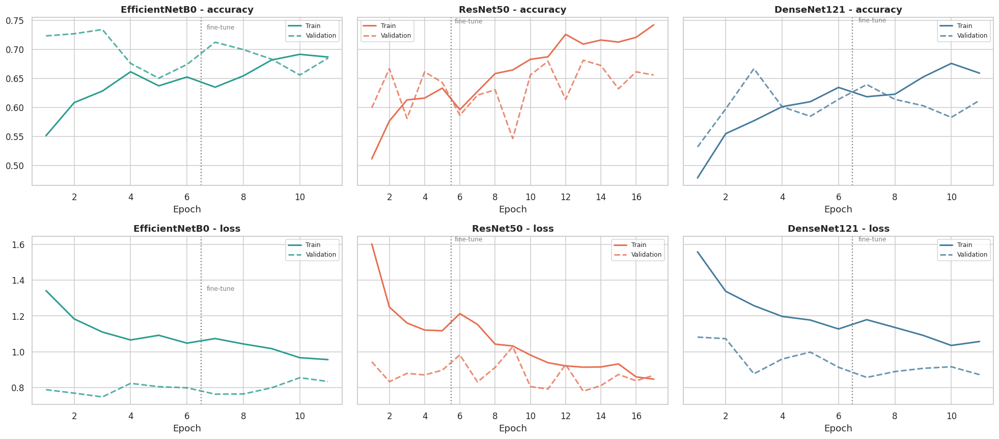

In [17]:
# Learning curves: dashed line marks the start of fine-tuning
fig, axes = plt.subplots(2, len(MODEL_ZOO), figsize=(6 * len(MODEL_ZOO), 8), sharey="row")
for col, name in enumerate(MODEL_ZOO):
    h, s1, c = RESULTS[name]["history"], RESULTS[name]["stage1_epochs"], MODEL_COLORS[name]
    epochs = np.arange(1, len(h["loss"]) + 1)
    for row, metric in enumerate(["accuracy", "loss"]):
        ax = axes[row, col]
        ax.plot(epochs, h[metric], color=c, lw=2, label="Train")
        ax.plot(epochs, h[f"val_{metric}"], color=c, lw=2, ls="--", alpha=0.8, label="Validation")
        ax.axvline(s1 + 0.5, color="grey", ls=":", lw=1.5)
        ax.text(s1 + 0.7, ax.get_ylim()[1], "fine-tune", va="top", fontsize=8, color="grey")
        ax.set_title(f"{name} - {metric}")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=8)
plt.tight_layout(); savefig("learning_curves.png"); plt.show()

## 6. Evaluation
**Metrics**
* **Accuracy** and **Macro-F1** over the 5 grades (Macro-F1 weights rare grades equally)
* **Quadratic Weighted Kappa (QWK)**, the official APTOS 2019 metric. It penalises a Proliferative-to-No-DR mistake far more than Mild-to-No-DR
* **Referable DR** (grade >= 2): P(referable) = P(Moderate) + P(Severe) + P(Proliferative). We report **ROC-AUC** and Sensitivity / Specificity / Precision / F1
  at a threshold picked **on the validation set** to reach >= 90 % sensitivity, the clinical priority being not to miss a patient who needs referral

In [18]:
def predict_probs(model, preprocess, split):
    return model.predict(make_dataset(split, preprocess), verbose=0)


def referable_score(probs):
    return probs[:, REFERABLE].sum(axis=1)


def pick_threshold(y_true, probs, target=TARGET_SENSITIVITY):
    # Highest threshold that still reaches the target sensitivity on validation data
    y_bin = np.isin(y_true, REFERABLE).astype(int)
    fpr, tpr, thr = roc_curve(y_bin, referable_score(probs))
    ok = np.where(tpr >= target)[0]
    return float(np.clip(thr[ok[0]], 0, 1))


def compute_metrics(y_true, probs, threshold):
    y_pred = probs.argmax(1)
    y_bin = np.isin(y_true, REFERABLE).astype(int)
    score = referable_score(probs)
    p_bin = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_bin, p_bin, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    return {
        "Accuracy":    accuracy_score(y_true, y_pred),
        "Macro F1":    f1_score(y_true, y_pred, average="macro", zero_division=0),
        "QWK":         cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        "Ref. AUC":    roc_auc_score(y_bin, score),
        "Sensitivity": sens,
        "Specificity": spec,
        "Precision":   prec,
        "Ref. F1":     2 * prec * sens / (prec + sens) if prec + sens else 0.0,
        "Threshold":   threshold,
    }


Y = {s: SPLITS[s].label.values for s in ("val", "test")}

for name, r in RESULTS.items():
    r["probs_val"]  = predict_probs(r["model"], r["preprocess"], "val")
    r["probs_test"] = predict_probs(r["model"], r["preprocess"], "test")
    r["threshold"]  = pick_threshold(Y["val"], r["probs_val"])
    r["metrics"]    = compute_metrics(Y["test"], r["probs_test"], r["threshold"])
    print(f"\n----- {name} (test set) -----")
    print(classification_report(Y["test"], r["probs_test"].argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0))
    pd.DataFrame(classification_report(Y["test"], r["probs_test"].argmax(1), target_names=CLASS_NAMES,
                                       output_dict=True, zero_division=0)).T.to_csv(out("metrics", f"{name}_classification_report.csv"))


----- EfficientNetB0 (test set) -----
               precision    recall  f1-score   support

        No DR     0.9129    0.9668    0.9391       271
         Mild     0.3614    0.5357    0.4317        56
     Moderate     0.7281    0.5533    0.6288       150
       Severe     0.3636    0.4138    0.3871        29
Proliferative     0.3333    0.2500    0.2857        44

     accuracy                         0.7236       550
    macro avg     0.5399    0.5439    0.5345       550
 weighted avg     0.7310    0.7236    0.7214       550


----- ResNet50 (test set) -----
               precision    recall  f1-score   support

        No DR     0.9427    0.9705    0.9564       271
         Mild     0.3830    0.6429    0.4800        56
     Moderate     0.6782    0.3933    0.4979       150
       Severe     0.2375    0.6552    0.3486        29
Proliferative     0.4000    0.0909    0.1481        44

     accuracy                         0.6927       550
    macro avg     0.5283    0.5506    0.486

## 7. Soft-voting ensemble
Averaging the three probability vectors cancels out individual models' errors; the three backbones make *different* mistakes.

               precision    recall  f1-score   support

        No DR     0.9362    0.9742    0.9548       271
         Mild     0.3936    0.6607    0.4933        56
     Moderate     0.8209    0.3667    0.5069       150
       Severe     0.2466    0.6207    0.3529        29
Proliferative     0.3529    0.2727    0.3077        44

     accuracy                         0.7018       550
    macro avg     0.5500    0.5790    0.5231       550
 weighted avg     0.7665    0.7018    0.7022       550



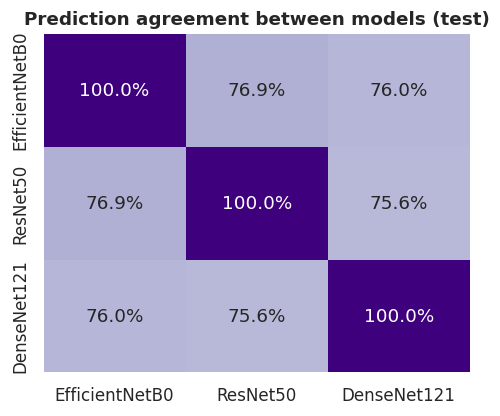

In [19]:
BASE_MODELS = list(MODEL_ZOO)
ens_val  = np.mean([RESULTS[m]["probs_val"]  for m in BASE_MODELS], axis=0)
ens_test = np.mean([RESULTS[m]["probs_test"] for m in BASE_MODELS], axis=0)
ens_thr  = pick_threshold(Y["val"], ens_val)

RESULTS["Ensemble"] = dict(probs_val=ens_val, probs_test=ens_test, threshold=ens_thr,
                           metrics=compute_metrics(Y["test"], ens_test, ens_thr))
print(classification_report(Y["test"], ens_test.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0))

# How much do the models disagree?
preds = {m: RESULTS[m]["probs_test"].argmax(1) for m in BASE_MODELS}
agree = pd.DataFrame([[np.mean(preds[a] == preds[b]) for b in BASE_MODELS] for a in BASE_MODELS],
                     index=BASE_MODELS, columns=BASE_MODELS)
plt.figure(figsize=(5, 4))
sns.heatmap(agree, annot=True, fmt=".1%", cmap="Purples", vmin=0.6, vmax=1, cbar=False)
plt.title("Prediction agreement between models (test)")
savefig("model_agreement.png"); plt.show()

## 8. Model comparison

In [20]:
ALL_MODELS = BASE_MODELS + ["Ensemble"]
comparison = pd.DataFrame({m: RESULTS[m]["metrics"] for m in ALL_MODELS}).T
comparison.to_csv(out("metrics", "model_comparison.csv"))

metric_cols = [c for c in comparison.columns if c != "Threshold"]
(comparison.style
    .format({c: "{:.2%}" for c in ["Accuracy", "Sensitivity", "Specificity", "Precision"]} |
            {c: "{:.4f}" for c in ["Macro F1", "QWK", "Ref. AUC", "Ref. F1", "Threshold"]})
    .highlight_max(subset=metric_cols, color="#c7e9c0")
    .set_caption("Held-out test set (best per column highlighted)"))

,Accuracy,Macro F1,QWK,Ref. AUC,Sensitivity,Specificity,Precision,Ref. F1,Threshold
EfficientNetB0,72.36%,0.5345,0.7762,0.9582,89.24%,88.99%,84.68%,0.8690,0.3313
ResNet50,69.27%,0.4862,0.7994,0.9651,91.93%,89.60%,85.77%,0.8874,0.2417
DenseNet121,64.55%,0.4583,0.7518,0.9501,90.58%,85.93%,81.45%,0.8577,0.3947
Ensemble,70.18%,0.5231,0.7906,0.9660,91.03%,89.91%,86.02%,0.8845,0.3589


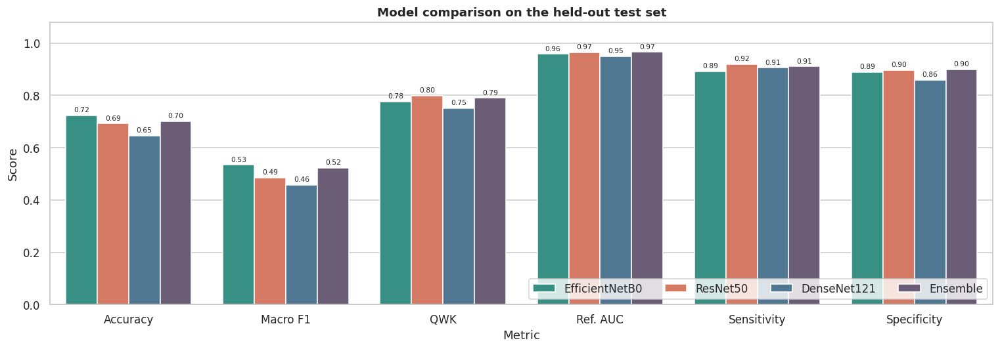

In [21]:
plot_metrics = ["Accuracy", "Macro F1", "QWK", "Ref. AUC", "Sensitivity", "Specificity"]
long = comparison[plot_metrics].reset_index(names="Model").melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=long, x="Metric", y="Score", hue="Model", palette=MODEL_COLORS)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)
ax.set_ylim(0, 1.08)
ax.set_title("Model comparison on the held-out test set")
ax.legend(loc="lower right", ncol=4)
plt.tight_layout(); savefig("comparison_bar.png"); plt.show()

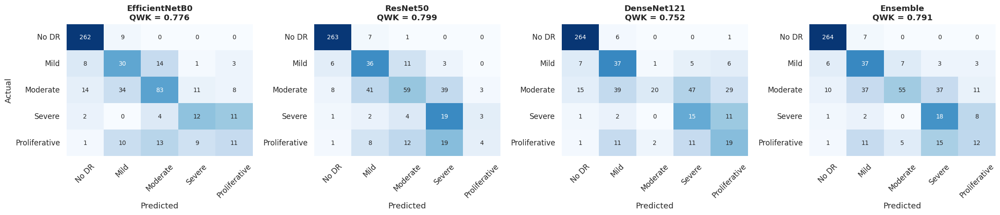

In [22]:
# Confusion matrices: row-normalised colour, raw counts annotated
fig, axes = plt.subplots(1, len(ALL_MODELS), figsize=(5.2 * len(ALL_MODELS), 4.6))
for ax, name in zip(axes, ALL_MODELS):
    cm = confusion_matrix(Y["test"], RESULTS[name]["probs_test"].argmax(1), labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 9})
    ax.set_title(f"{name}\nQWK = {RESULTS[name]['metrics']['QWK']:.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("confusion_matrices.png"); plt.show()

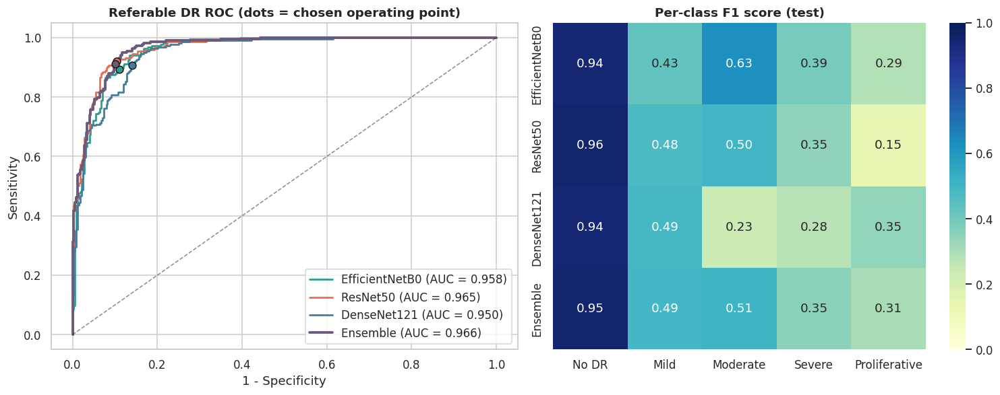

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC curves for referable DR
y_bin = np.isin(Y["test"], REFERABLE).astype(int)
for name in ALL_MODELS:
    fpr, tpr, _ = roc_curve(y_bin, referable_score(RESULTS[name]["probs_test"]))
    m = RESULTS[name]["metrics"]
    ax[0].plot(fpr, tpr, lw=2.5 if name == "Ensemble" else 1.8, color=MODEL_COLORS[name],
               label=f"{name} (AUC = {m['Ref. AUC']:.3f})")
    ax[0].scatter(1 - m["Specificity"], m["Sensitivity"], color=MODEL_COLORS[name], s=50, zorder=5, edgecolor="k")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
ax[0].set(xlabel="1 - Specificity", ylabel="Sensitivity", title="Referable DR ROC (dots = chosen operating point)")
ax[0].legend(loc="lower right")

# Per-class F1
f1_table = pd.DataFrame({
    name: f1_score(Y["test"], RESULTS[name]["probs_test"].argmax(1), average=None, labels=range(NUM_CLASSES), zero_division=0)
    for name in ALL_MODELS}, index=CLASS_NAMES).T
sns.heatmap(f1_table, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Per-class F1 score (test)")
plt.tight_layout(); savefig("roc_and_per_class_f1.png"); plt.show()

### 8.1 Deployment efficiency
For screening in rural Primary Health Centres the model must run on modest hardware, so we also compare size and speed.

,Params (M),Model size (MB),Latency (ms / image),Training time (min),Test QWK
EfficientNetB0,4.379,42.217,10.110,6.827,0.776
ResNet50,24.114,227.798,7.604,10.198,0.799
DenseNet121,7.301,42.714,14.936,8.394,0.752


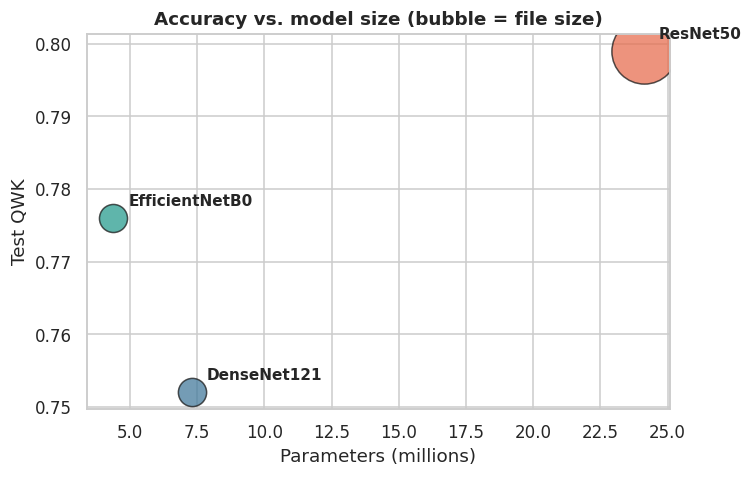

In [24]:
def latency_ms(model, n_runs=10):
    x = tf.random.uniform((BATCH_SIZE, *IMG_SIZE, 3), 0, 255)
    model(x, training=False)                    # warm-up
    t0 = time.perf_counter()
    for _ in range(n_runs):
        model(x, training=False)
    return (time.perf_counter() - t0) / (n_runs * BATCH_SIZE) * 1000

eff = pd.DataFrame({
    name: {"Params (M)": RESULTS[name]["params"] / 1e6,
           "Model size (MB)": RESULTS[name]["size_mb"],
           "Latency (ms / image)": latency_ms(RESULTS[name]["model"]),
           "Training time (min)": RESULTS[name]["train_time_min"],
           "Test QWK": RESULTS[name]["metrics"]["QWK"]}
    for name in BASE_MODELS}).T.round(3)
eff.to_csv(out("metrics", "efficiency.csv"))
display(eff)

plt.figure(figsize=(7, 4.5))
for name in BASE_MODELS:
    plt.scatter(eff.loc[name, "Params (M)"], eff.loc[name, "Test QWK"], s=eff.loc[name, "Model size (MB)"] * 8,
                color=MODEL_COLORS[name], alpha=0.75, edgecolor="k")
    plt.annotate(name, (eff.loc[name, "Params (M)"], eff.loc[name, "Test QWK"]),
                 textcoords="offset points", xytext=(10, 8), fontsize=10, fontweight="bold")
plt.xlabel("Parameters (millions)"); plt.ylabel("Test QWK")
plt.title("Accuracy vs. model size (bubble = file size)")
plt.tight_layout(); savefig("efficiency.png"); plt.show()

## 9. Grad-CAM explainability
Grad-CAM weights the backbone's **last convolutional feature maps** by the gradient of the predicted class score, which shows *where*
each network looks. One test image per grade, all three models side by side. Clinically meaningful maps highlight lesions (haemorrhages,
exudates, neovascularisation), not the optic disc or the image border.

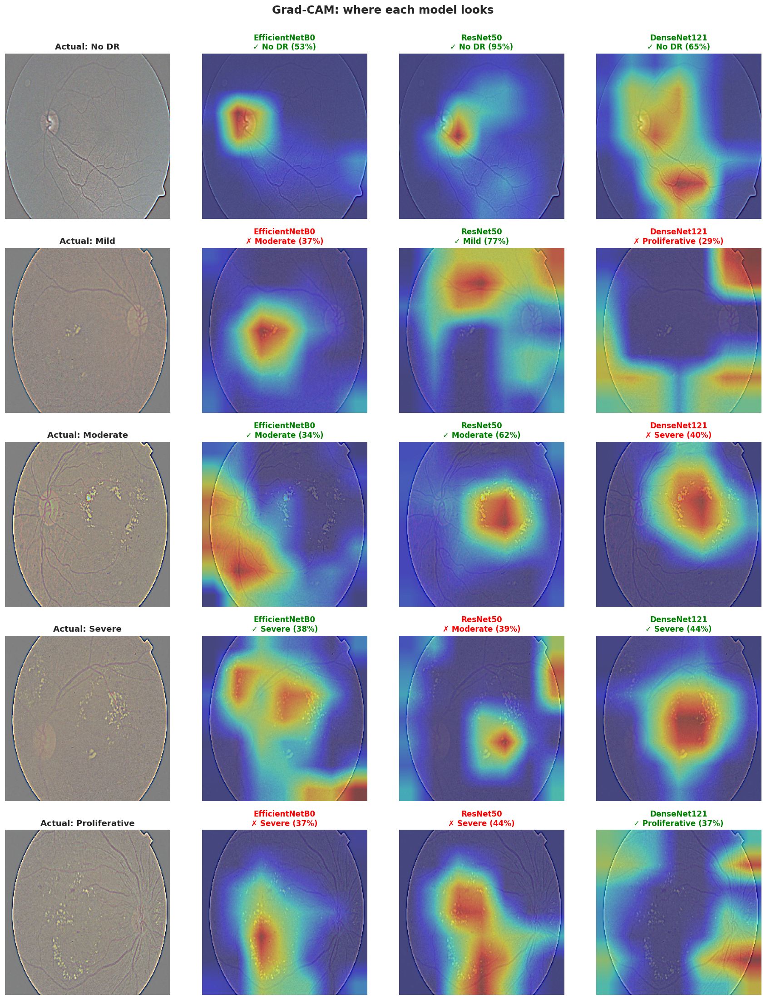

In [25]:
def grad_cam(name, raw_img):
    r = RESULTS[name]
    x = r["preprocess"](tf.cast(raw_img[None], tf.float32))
    with tf.GradientTape() as tape:
        feats = r["backbone"](x, training=False)       # last conv feature maps
        tape.watch(feats)
        y = feats
        for layer in r["head"]:
            y = layer(y, training=False)
        cls = int(tf.argmax(y[0]))
        score = y[:, cls]
    grads = tape.gradient(score, feats)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(feats * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
    return cam, cls, float(y[0, cls])


samples = SPLITS["test"].groupby("label", group_keys=False).sample(1, random_state=SEED)
fig, axes = plt.subplots(len(samples), 1 + len(BASE_MODELS), figsize=(4 * (1 + len(BASE_MODELS)), 4 * len(samples)))
for row, (_, s) in enumerate(samples.iterrows()):
    img = load_image(s.path).numpy()
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Actual: {CLASS_NAMES[s.label]}", fontsize=12)
    for col, name in enumerate(BASE_MODELS, start=1):
        cam, cls, conf = grad_cam(name, img)
        ax = axes[row, col]
        ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.45)
        ok = cls == s.label
        ax.set_title(f"{name}\n{'✓' if ok else '✗'} {CLASS_NAMES[cls]} ({conf:.0%})",
                     fontsize=11, color="green" if ok else "red")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Grad-CAM: where each model looks", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout(); savefig("gradcam_comparison.png"); plt.show()

## 10. Screening demo: one image to triage decision
What a health worker at a PHC would see: ensemble grade, confidence, referral decision and an explanation heatmap.

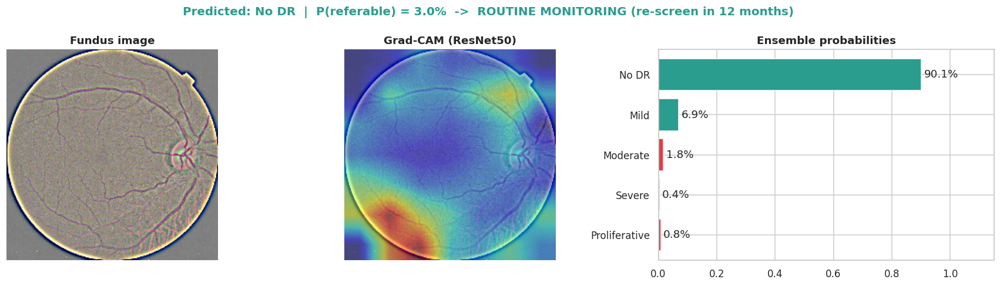

{'grade': 'No DR', 'p_referable': 0.03, 'refer': False}


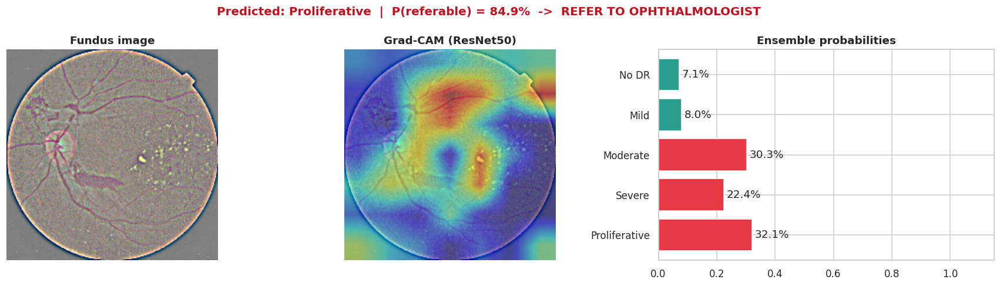

{'grade': 'Proliferative', 'p_referable': 0.8489, 'refer': True}


In [26]:
def screen(image_path):
    img = load_image(image_path).numpy()
    probs = np.mean([RESULTS[m]["model"].predict(RESULTS[m]["preprocess"](tf.cast(img[None], tf.float32)), verbose=0)[0]
                     for m in BASE_MODELS], axis=0)
    grade = int(probs.argmax())
    p_ref = float(probs[REFERABLE].sum())
    refer = p_ref >= RESULTS["Ensemble"]["threshold"]
    best = max(BASE_MODELS, key=lambda m: RESULTS[m]["metrics"]["QWK"])
    cam, _, _ = grad_cam(best, img)

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
    ax[0].imshow(img); ax[0].set_title("Fundus image"); ax[0].axis("off")
    ax[1].imshow(img); ax[1].imshow(cam, cmap="jet", alpha=0.45)
    ax[1].set_title(f"Grad-CAM ({best})"); ax[1].axis("off")
    bars = ax[2].barh(CLASS_NAMES, probs, color=["#2a9d8f"] * 2 + ["#e63946"] * 3)
    ax[2].bar_label(bars, labels=[f"{p:.1%}" for p in probs], padding=3)
    ax[2].set_xlim(0, 1.15); ax[2].invert_yaxis(); ax[2].set_title("Ensemble probabilities")
    verdict = "REFER TO OPHTHALMOLOGIST" if refer else "ROUTINE MONITORING (re-screen in 12 months)"
    fig.suptitle(f"Predicted: {CLASS_NAMES[grade]}  |  P(referable) = {p_ref:.1%}  ->  {verdict}",
                 fontsize=13, fontweight="bold", color="#c1121f" if refer else "#2a9d8f")
    plt.tight_layout(); plt.show()
    return {"grade": CLASS_NAMES[grade], "p_referable": round(p_ref, 4), "refer": bool(refer)}


for p in SPLITS["test"].groupby("label", group_keys=False).sample(1, random_state=7).path.values[[0, 4]]:
    print(screen(p))

## 11. Summary

In [27]:
best = {metric: comparison[metric].idxmax() for metric in metric_cols}
print("Best model per metric (test set)")
print("-" * 45)
for metric, model_name in best.items():
    print(f"{metric:<13} {model_name:<16} {comparison.loc[model_name, metric]:.4f}")

with open(out("metrics", "summary.json"), "w") as f:
    json.dump({"comparison": comparison.round(4).to_dict(orient="index"),
               "efficiency": eff.to_dict(orient="index"), "best_per_metric": best}, f, indent=2)
print("\nAll models, figures and metrics saved under:", os.path.abspath(OUTPUT_DIR))

Best model per metric (test set)
---------------------------------------------
Accuracy      EfficientNetB0   0.7236
Macro F1      EfficientNetB0   0.5345
QWK           ResNet50         0.7994
Ref. AUC      Ensemble         0.9660
Sensitivity   ResNet50         0.9193
Specificity   Ensemble         0.8991
Precision     Ensemble         0.8602
Ref. F1       ResNet50         0.8874

All models, figures and metrics saved under: /content/DR_Project_MultiModel


### Key takeaways (fill in after running)
* **Best single model:** _..._ (QWK _..._, referable AUC _..._)
* **Ensemble** vs best single model: _..._
* **Most efficient:** EfficientNetB0, about 4 M params and the smallest file, the best fit for edge deployment at PHCs
* **Hardest grades:** Severe and Proliferative (few samples), the main target for future work
* **Grad-CAM:** _which model's heatmaps focus on lesions rather than the optic disc / borders_

### Future scope
Larger and more diverse datasets (EyePACS, Messidor-2, IDRiD), higher resolution (380-512 px), ordinal / regression loss,
TFLite quantisation for on-device inference, and prospective validation in rural PHCs.